In [1]:
!pip install requests beautifulsoup4 pandas 

In [4]:
import requests
from bs4 import BeautifulSoup

url = "https://books.toscrape.com/"

response = requests.get(url,timeout=20)
print("Status Code:",response.status_code)

soup = BeautifulSoup(response.text,"html.parser")
print(soup.title.text)

Status Code: 200

    All products | Books to Scrape - Sandbox



In [5]:
books = soup.find_all("article", class_="product_pod")

for book in books:
    name = book.h3.a["title"]
    price = book.find("p", class_="price_color").text
    rating = book.find("p", class_="star-rating")["class"][1]

    print(name, "|", price, "|", rating)

A Light in the Attic | Â£51.77 | Three
Tipping the Velvet | Â£53.74 | One
Soumission | Â£50.10 | One
Sharp Objects | Â£47.82 | Four
Sapiens: A Brief History of Humankind | Â£54.23 | Five
The Requiem Red | Â£22.65 | One
The Dirty Little Secrets of Getting Your Dream Job | Â£33.34 | Four
The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull | Â£17.93 | Three
The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 1936 Berlin Olympics | Â£22.60 | Four
The Black Maria | Â£52.15 | One
Starving Hearts (Triangular Trade Trilogy, #1) | Â£13.99 | Two
Shakespeare's Sonnets | Â£20.66 | Four
Set Me Free | Â£17.46 | Five
Scott Pilgrim's Precious Little Life (Scott Pilgrim #1) | Â£52.29 | Five
Rip it Up and Start Again | Â£35.02 | Five
Our Band Could Be Your Life: Scenes from the American Indie Underground, 1981-1991 | Â£57.25 | Three
Olio | Â£23.88 | One
Mesaerion: The Best Science Fiction Stories 1800-1849 | Â£37.59 | One
Libertarianism for Begin

In [6]:
import pandas as pd

data = []

for book in books:
    name = book.h3.a["title"]
    price = book.find("p", class_="price_color").text
    rating = book.find("p", class_="star-rating")["class"][1]

    data.append({
        "Book Name": name,
        "Price": price,
        "Rating": rating
    })

df = pd.DataFrame(data)

df.to_csv("books_dataset.csv", index=False)

print(df.head())
print("Total books:", len(df))

                               Book Name    Price Rating
0                   A Light in the Attic  Â£51.77  Three
1                     Tipping the Velvet  Â£53.74    One
2                             Soumission  Â£50.10    One
3                          Sharp Objects  Â£47.82   Four
4  Sapiens: A Brief History of Humankind  Â£54.23   Five
Total books: 20


In [7]:
print(df.shape)
print(df.isnull().sum())
print(df.info())

(20, 3)
Book Name    0
Price        0
Rating       0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Book Name  20 non-null     object
 1   Price      20 non-null     object
 2   Rating     20 non-null     object
dtypes: object(3)
memory usage: 612.0+ bytes
None


0    51.77
1    53.74
2    50.10
3    47.82
4    54.23
Name: Price, dtype: float64


C:\Users\ammub\AppData\Local\Temp\ipykernel_1904\287506486.py:28: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


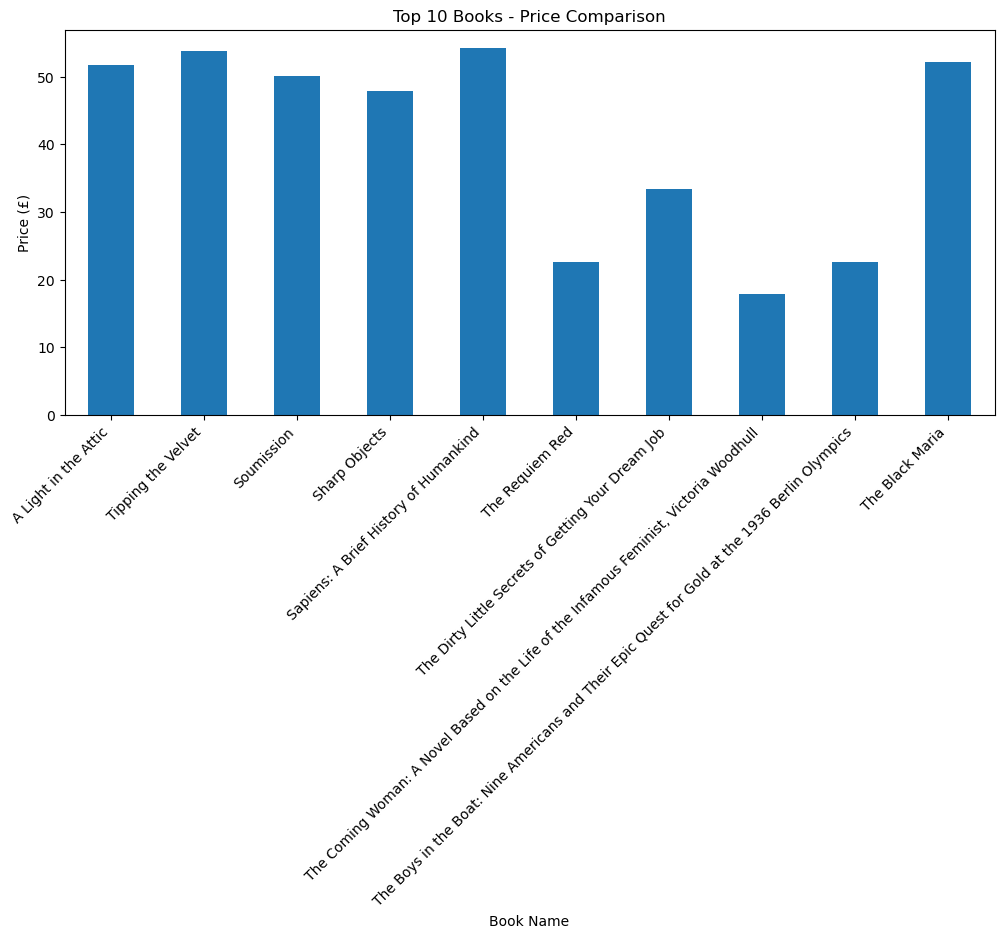

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

df["Price"] = (
    df["Price"]
    .astype(str)
    .str.replace("£", "", regex=False)
    .str.replace("Â", "", regex=False)
    .str.strip()
)

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

print(df["Price"].head())

df.head(10).plot(
    x="Book Name",
    y="Price",
    kind="bar",
    figsize=(12, 5),
    legend=False
)

plt.title("Top 10 Books - Price Comparison")
plt.xlabel("Book Name")
plt.ylabel("Price (£)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [10]:
print(df.head(10))
print("Total books:", len(df))
print(df.isnull().sum())

                                           Book Name  Price Rating
0                               A Light in the Attic  51.77  Three
1                                 Tipping the Velvet  53.74    One
2                                         Soumission  50.10    One
3                                      Sharp Objects  47.82   Four
4              Sapiens: A Brief History of Humankind  54.23   Five
5                                    The Requiem Red  22.65    One
6  The Dirty Little Secrets of Getting Your Dream...  33.34   Four
7  The Coming Woman: A Novel Based on the Life of...  17.93  Three
8  The Boys in the Boat: Nine Americans and Their...  22.60   Four
9                                    The Black Maria  52.15    One
Total books: 20
Book Name    0
Price        0
Rating       0
dtype: int64
